In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import TensorDataset, DataLoader, Dataset
import torch.nn as nn
from tqdm.notebook import tqdm
from sklearn.preprocessing import StandardScaler
import joblib
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import copy
import seaborn as sns
import random
import re
from scipy.stats import spearmanr

In [1130]:
df0404 = pd.read_csv("../data/labeledAndAnomaly/no_plug/0404.csv")
df0712 = pd.read_csv("../data/labeledAndAnomaly/no_plug/0712.csv")
df1703 = pd.read_csv("../data/labeledAndAnomaly/no_plug/1703.csv")
df2906_1 = pd.read_csv("../data/labeledAndAnomaly/no_plug/2906-1.csv")
df3006_1 = pd.read_csv("../data/labeledAndAnomaly/no_plug/3006-1.csv")
df3006_2 = pd.read_csv("../data/labeledAndAnomaly/no_plug/3006-2.csv")

df1103 = pd.read_csv("../data/labeledAndAnomaly/partial_plug/1103.csv")
df1803 = pd.read_csv("../data/labeledAndAnomaly/partial_plug/1803.csv")
df2503 = pd.read_csv("../data/labeledAndAnomaly/partial_plug/2503.csv")
df2108_1 = pd.read_csv("../data/labeledAndAnomaly/partial_plug/2108-1.csv")


df0612_2 = pd.read_csv("../data/labeledAndAnomaly/plug/0612-2.csv")
df0612_3 = pd.read_csv("../data/labeledAndAnomaly/plug/0612-3.csv")
df0707_1 = pd.read_csv("../data/labeledAndAnomaly/plug/0707-1.csv")
df0707_2 = pd.read_csv("../data/labeledAndAnomaly/plug/0707-2.csv")
df0707_4 = pd.read_csv("../data/labeledAndAnomaly/plug/0707-4.csv")
df0709 = pd.read_csv("../data/labeledAndAnomaly/plug/0709.csv")
df1003 = pd.read_csv("../data/labeledAndAnomaly/plug/1003.csv")
df1112 = pd.read_csv("../data/labeledAndAnomaly/plug/1112.csv")
df1310_2 = pd.read_csv("../data/labeledAndAnomaly/plug/1310-2.csv")
df1310_3 = pd.read_csv("../data/labeledAndAnomaly/plug/1310-3.csv")
df1407_1 = pd.read_csv("../data/labeledAndAnomaly/plug/1407-1.csv")
df1407_2 = pd.read_csv("../data/labeledAndAnomaly/plug/1407-2.csv")
df1407_3 = pd.read_csv("../data/labeledAndAnomaly/plug/1407-3.csv")
df1407_4 = pd.read_csv("../data/labeledAndAnomaly/plug/1407-4.csv")
df1503 = pd.read_csv("../data/labeledAndAnomaly/plug/1503.csv")
df1811 = pd.read_csv("../data/labeledAndAnomaly/plug/1811.csv")
df2106_2 = pd.read_csv("../data/labeledAndAnomaly/plug/2106-2.csv")
df2108_2 = pd.read_csv("../data/labeledAndAnomaly/plug/2108-2.csv")
df2701 = pd.read_csv("../data/labeledAndAnomaly/plug/2701.csv")
df2906_2 = pd.read_csv("../data/labeledAndAnomaly/plug/2906-2.csv")
df2906_3 = pd.read_csv("../data/labeledAndAnomaly/plug/2906-3.csv")
df2906_4 = pd.read_csv("../data/labeledAndAnomaly/plug/2906-4.csv")
df3006_3 = pd.read_csv("../data/labeledAndAnomaly/plug/3006-3.csv")

In [1131]:
no_plug_dfs = [df0404, df0712, df1703, df2906_1, df3006_1, df3006_2]
plug_dfs =  [df0612_2, df0612_3, df0707_1, df0707_2, df0707_4, df0709, df1003, df1112, df1310_2, df1310_3,
            df1407_1, df1407_2, df1407_3, df1407_4, df1503, df1811, df2106_2, df2108_2, df2701, 
            df2906_2, df2906_3, df2906_4, df3006_3]
partial_plug_dfs = [df1103, df1803, df2503, df2108_1]

In [1132]:
no_plug_names = ['0404', '0712', '1703', '2906-1', '3006-1', '3006-2']

plug_names = ['0612-2', '0612-3', '0707-1', '0707-2', '0707-4', '0709', '1003', '1112',
              '1310-2', '1310-3', '1407-1', '1407-2', '1407-3', '1407-4', '1503', '1811',
              '2106-2', '2108-2', '2701', '2906-2', '2906-3', '2906-4', '3006-3']

partial_plug_names = ['1103', '1803', '2503', '2108-1']

In [ ]:
def prepare_phase_stratified_split(
    all_runs,
    feature_cols,
    window_size=60,
    train_ratio=0.60,
    val_ratio=0.20
):
    X_train_list, y_train_list, groups_train = [], [], []
    X_val_list, y_val_list, groups_val = [], [], []
    X_test_list, y_test_list, groups_test = [], [], []

    for run_id, df in enumerate(all_runs):
        df_run = (
            df.sort_values('elapsed_runtime_s')
              .reset_index(drop=True)
              .copy()
        )

        df_run['state_block'] = (
            df_run['label'] != df_run['label'].shift(1)
        ).cumsum()

        for block_id, block in df_run.groupby('state_block'):
            block = block.reset_index(drop=True)

            n_samples = len(block)

            train_end = int(n_samples * train_ratio)
            val_end = int(n_samples * (train_ratio + val_ratio))

            train_block = block.iloc[:train_end]
            val_block = block.iloc[train_end:val_end]
            test_block = block.iloc[val_end:]

            # -------------------------
            # TRAIN WINDOWS
            # -------------------------
            train_vals = train_block[feature_cols].values
            train_labels = train_block['label'].values

            for i in range(window_size, len(train_vals)):
                X_train_list.append(
                    train_vals[i - window_size:i]
                )
                y_train_list.append(train_labels[i])
                groups_train.append(run_id)

            # -------------------------
            # VALIDATION WINDOWS
            # -------------------------
            val_vals = val_block[feature_cols].values
            val_labels = val_block['label'].values

            for i in range(window_size, len(val_vals)):
                X_val_list.append(
                    val_vals[i - window_size:i]
                )
                y_val_list.append(val_labels[i])
                groups_val.append(run_id)

            # -------------------------
            # TEST WINDOWS
            # -------------------------
            test_vals = test_block[feature_cols].values
            test_labels = test_block['label'].values

            for i in range(window_size, len(test_vals)):
                X_test_list.append(
                    test_vals[i - window_size:i]
                )
                y_test_list.append(test_labels[i])
                groups_test.append(run_id)

    X_train = np.array(X_train_list, dtype=np.float32)
    y_train = np.array(y_train_list, dtype=np.int64)

    X_val = np.array(X_val_list, dtype=np.float32)
    y_val = np.array(y_val_list, dtype=np.int64)

    X_test = np.array(X_test_list, dtype=np.float32)
    y_test = np.array(y_test_list, dtype=np.int64)

    return (
        X_train, y_train,
        X_val, y_val,
        X_test, y_test,
        np.array(groups_train),
        np.array(groups_val),
        np.array(groups_test)
    )

In [1134]:
all_runs = no_plug_dfs + plug_dfs + partial_plug_dfs

ORIGINAL_FEATURES = [
    'rel_tot_dp_change',
    'rel_ts_dp_change',
    'rel_p_ts_dp_change',
    'Relative_Ratio_Dev'
]

X_tr, y_tr, X_val, y_val, X_te, y_te, g_tr, g_val, g_te = (
    prepare_phase_stratified_split(
        all_runs=all_runs,
        feature_cols=ORIGINAL_FEATURES,
    )
)

print(f"Train Shapes: X={X_tr.shape}, y={y_tr.shape}")
print(f"Val Shapes:   X={X_val.shape}, y={y_val.shape}")
print(f"Test Shapes:  X={X_te.shape}, y={y_te.shape}")

Train Shapes: X=(94584, 60, 4), y=(94584,)
Val Shapes:   X=(29010, 60, 4), y=(29010,)
Test Shapes:  X=(29018, 60, 4), y=(29018,)


In [1135]:
N_tr, S_tr, F_tr = X_tr.shape

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_tr.reshape(-1, F_tr)
).reshape(N_tr, S_tr, F_tr)

joblib.dump(scaler, '../models/no_a_lstm_scaler.joblib')

['../models/no_a_lstm_scaler.joblib']

In [1136]:
X_val_scaled = scaler.transform(
    X_val.reshape(-1, F_tr)
).reshape(*X_val.shape)

X_test_scaled = scaler.transform(
    X_te.reshape(-1, F_tr)
).reshape(*X_te.shape)

In [1137]:
# --- 4. Dataset & DataLoader ---
class SequenceDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
        
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [1138]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [1139]:
set_seed(1908)

train_loader = DataLoader(
    SequenceDataset(X_train_scaled, y_tr),
    batch_size=256,
    shuffle=True
)

val_loader = DataLoader(
    SequenceDataset(X_val_scaled, y_val),
    batch_size=512,
    shuffle=False
)

test_loader = DataLoader(
    SequenceDataset(X_test_scaled, y_te),
    batch_size=512,
    shuffle=False
)

In [1140]:
class PlainLSTM(nn.Module):
    def __init__(self, input_dim=4, hidden_dim=32, num_layers=1, num_classes=4, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers=num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(self.drop(out[:, -1, :]))

In [1141]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
mean_t = torch.tensor(scaler.mean_,  dtype=torch.float32, device=device)
std_t  = torch.tensor(scaler.scale_, dtype=torch.float32, device=device)
model = PlainLSTM(input_dim=F_tr, hidden_dim=32, num_layers=1, dropout=0.4).to(device)

In [1142]:
# 1. Calculate class frequencies directly from y_tr
class_counts = np.bincount(y_tr)
total_samples = len(y_tr)

# 2. Compute balanced inverse weights
class_weights = total_samples / (len(class_counts) * class_counts)

# 3. Apply a modest boost to Class 3 to suppress Class 3 -> Class 0/1 leaks
class_weights[3] *= 1.1

# 4. Pass weights to loss function (moves to device automatically with model/data)
weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=weights_tensor)

In [1143]:
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=3
)

In [1144]:
def augment_scaled(x_s, mean, std, gain_sigma=0.3, offset_sigma=0.3,
                   noise_sigma=0.1, channel_drop=0.2):
    B, T, F = x_s.shape
    g = torch.exp(torch.randn(B, 1, F, device=x_s.device) * gain_sigma)
    x_s = x_s * g + (g - 1) * (mean / std)                 # gain applied to the raw value
    x_s = x_s + torch.randn(B, 1, F, device=x_s.device) * offset_sigma
    x_s = x_s + torch.randn_like(x_s) * noise_sigma
    if channel_drop > 0:
        keep = (torch.rand(B, 1, F, device=x_s.device) > channel_drop).float()
        x_s = x_s * keep                                    # zero whole channels (= feature set to its mean)
    return x_s

In [1145]:
# --- 6. Training Loop ---
EPOCHS = 100
PATIENCE = 10
patience_counter = 0
best_val_loss = float('inf')

print(f"Training Baseline-Subtracted LSTM on {device}...\n")

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0
    
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        batch_X = augment_scaled(batch_X, mean_t, std_t) 
        
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        
        train_loss += loss.item() * batch_X.size(0)
        preds = torch.argmax(outputs, dim=1)
        train_correct += (preds == batch_y).sum().item()
        train_total += batch_y.size(0)
        
    epoch_train_loss = train_loss / train_total
    epoch_train_acc = (train_correct / train_total) * 100

    # Validation
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for batch_X, batch_y in val_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            
            val_loss += loss.item() * batch_X.size(0)
            preds = torch.argmax(outputs, dim=1)
            val_correct += (preds == batch_y).sum().item()
            val_total += batch_y.size(0)
            
    epoch_val_loss = val_loss / val_total
    epoch_val_acc = (val_correct / val_total) * 100

    scheduler.step(epoch_val_loss)

    # Check validation loss improvement
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), '../models/no_a_lstm.pth')
        patience_counter = 0  # Reset patience counter on improvement
        saved_msg = "   New Best Val Loss! Weights saved to 'no_a_lstm.pth'"
    else:
        patience_counter += 1
        saved_msg = f'   [No Improvement ({patience_counter}/{PATIENCE})]'

    current_lr = optimizer.param_groups[0]['lr']
    print(
      f'Epoch [{epoch:02d}/{EPOCHS:02d}] | LR: {current_lr:.1e} | [TRAIN]'
      f' Loss: {epoch_train_loss:.4f} | Acc: {epoch_train_acc:.2f}% [VALID]'
      f' Loss: {epoch_val_loss:.4f} | Acc: {epoch_val_acc:.2f}%{saved_msg}'
    )

    # Early stopping trigger
    if patience_counter >= PATIENCE:
        print(
            f'\nEarly stopping triggered at Epoch {epoch}'
        )
        break

Training Baseline-Subtracted LSTM on cpu...

Epoch [01/100] | LR: 1.0e-03 | [TRAIN] Loss: 1.0695 | Acc: 53.15% [VALID] Loss: 0.9024 | Acc: 62.73%   New Best Val Loss! Weights saved to 'no_a_lstm.pth'
Epoch [02/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.9913 | Acc: 55.12% [VALID] Loss: 0.8850 | Acc: 62.12%   New Best Val Loss! Weights saved to 'no_a_lstm.pth'
Epoch [03/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.9811 | Acc: 54.59% [VALID] Loss: 0.8580 | Acc: 62.78%   New Best Val Loss! Weights saved to 'no_a_lstm.pth'
Epoch [04/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.9735 | Acc: 54.59% [VALID] Loss: 0.8774 | Acc: 63.26%   [No Improvement (1/10)]
Epoch [05/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.9743 | Acc: 54.35% [VALID] Loss: 0.8709 | Acc: 61.63%   [No Improvement (2/10)]
Epoch [06/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.9631 | Acc: 55.00% [VALID] Loss: 0.8580 | Acc: 60.03%   [No Improvement (3/10)]
Epoch [07/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.9623 | Acc: 55.00% [VALID] Loss: 0.8509 | Acc: 62.89%   New Be


================ VALIDATION BENCHMARK ================
Overall Accuracy: 64.59%

              precision    recall  f1-score   support

           0       0.95      0.62      0.75     15435
           1       0.22      0.97      0.35      2735
           2       0.97      0.57      0.72      9517
           3       0.94      0.81      0.87      1323

    accuracy                           0.65     29010
   macro avg       0.77      0.74      0.67     29010
weighted avg       0.89      0.65      0.71     29010



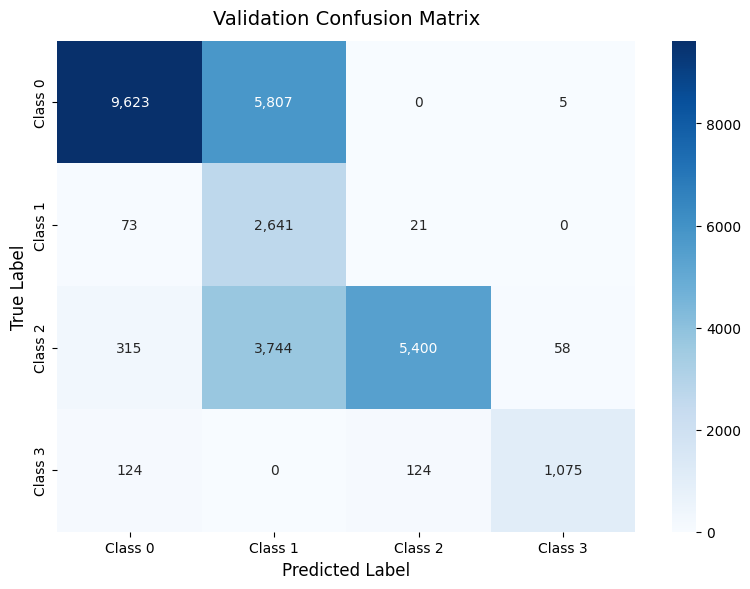

In [1146]:
# --- Validation Evaluation & Confusion Matrix ---
model.load_state_dict(
    torch.load('../models/no_a_lstm.pth', map_location=device)
)
model.eval()

val_preds, val_targets = [], []

with torch.no_grad():
    for batch_X, batch_y in val_loader:
        batch_X = batch_X.to(device)

        outputs = model(batch_X)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()

        val_preds.extend(preds)
        val_targets.extend(batch_y.numpy())

print("\n================ VALIDATION BENCHMARK ================")
print(
    f"Overall Accuracy: "
    f"{accuracy_score(val_targets, val_preds) * 100:.2f}%\n"
)

print(
    classification_report(
        val_targets,
        val_preds,
        digits=2
    )
)

cm_val = confusion_matrix(val_targets, val_preds)

class_names = [
    'Class 0',
    'Class 1',
    'Class 2',
    'Class 3'
]

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    cm_val,
    annot=True,
    fmt=',d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    ax=ax
)

plt.title(
    'Validation Confusion Matrix',
    fontsize=14,
    pad=12
)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)

plt.tight_layout()
plt.show()

In [1147]:
# --- 7. Test Evaluation & Confusion Matrix ---
model.load_state_dict(torch.load('../models/no_a_lstm.pth', map_location=device))
model.eval()
all_preds, all_targets = [], []
with torch.no_grad():
    for batch_X, batch_y in test_loader:
        batch_X = batch_X.to(device)
        preds = torch.argmax(model(batch_X), dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(batch_y.numpy())

print("\n================ TEST BENCHMARK ================")
print(f"Overall Accuracy: {accuracy_score(all_targets, all_preds) * 100:.2f}%\n")
print(classification_report(all_targets, all_preds, digits=2))


================ TEST BENCHMARK ================
Overall Accuracy: 64.96%

              precision    recall  f1-score   support

           0       0.97      0.64      0.77     15437
           1       0.20      0.87      0.33      2735
           2       0.92      0.61      0.74      9520
           3       0.91      0.58      0.71      1326

    accuracy                           0.65     29018
   macro avg       0.75      0.68      0.64     29018
weighted avg       0.88      0.65      0.72     29018



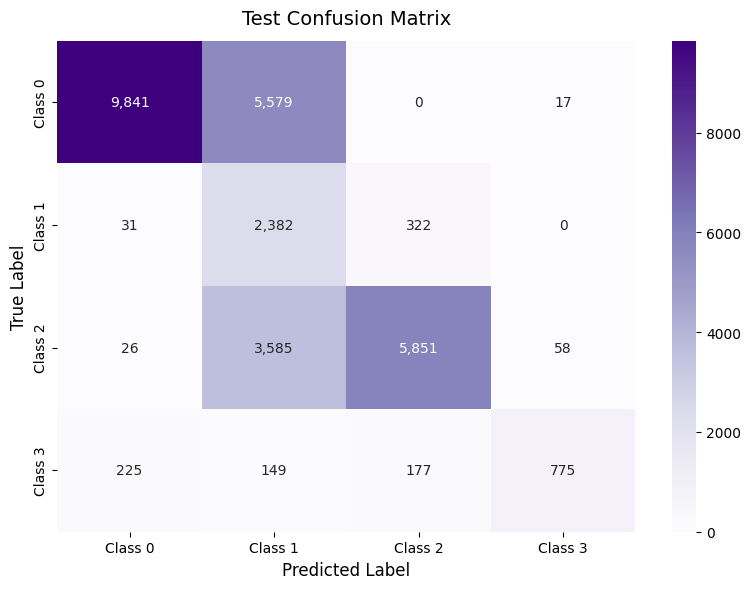

In [1148]:
cm = confusion_matrix(all_targets, all_preds)
class_names = ['Class 0', 'Class 1', 'Class 2', 'Class 3']

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt=',d', cmap='Purples', xticklabels=class_names, yticklabels=class_names, ax=ax)
plt.title('Test Confusion Matrix', fontsize=14, pad=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

In [1156]:
log = """Epoch [01/100] | LR: 1.0e-03 | [TRAIN] Loss: 1.0695 | Acc: 53.15% [VALID] Loss: 0.9024 | Acc: 62.73%   New Best Val Loss! Weights saved to 'no_a_lstm.pth'
Epoch [02/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.9913 | Acc: 55.12% [VALID] Loss: 0.8850 | Acc: 62.12%   New Best Val Loss! Weights saved to 'no_a_lstm.pth'
Epoch [03/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.9811 | Acc: 54.59% [VALID] Loss: 0.8580 | Acc: 62.78%   New Best Val Loss! Weights saved to 'no_a_lstm.pth'
Epoch [04/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.9735 | Acc: 54.59% [VALID] Loss: 0.8774 | Acc: 63.26%   [No Improvement (1/10)]
Epoch [05/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.9743 | Acc: 54.35% [VALID] Loss: 0.8709 | Acc: 61.63%   [No Improvement (2/10)]
Epoch [06/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.9631 | Acc: 55.00% [VALID] Loss: 0.8580 | Acc: 60.03%   [No Improvement (3/10)]
Epoch [07/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.9623 | Acc: 55.00% [VALID] Loss: 0.8509 | Acc: 62.89%   New Best Val Loss! Weights saved to 'no_a_lstm.pth'
Epoch [08/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.9643 | Acc: 54.71% [VALID] Loss: 0.8636 | Acc: 61.23%   [No Improvement (1/10)]
Epoch [09/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.9575 | Acc: 55.69% [VALID] Loss: 0.8554 | Acc: 58.09%   [No Improvement (2/10)]
Epoch [10/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.9554 | Acc: 55.23% [VALID] Loss: 0.8257 | Acc: 67.42%   New Best Val Loss! Weights saved to 'no_a_lstm.pth'
Epoch [11/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.9539 | Acc: 55.70% [VALID] Loss: 0.8316 | Acc: 61.59%   [No Improvement (1/10)]
Epoch [12/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.9476 | Acc: 56.15% [VALID] Loss: 0.8173 | Acc: 64.93%   New Best Val Loss! Weights saved to 'no_a_lstm.pth'
Epoch [13/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.9485 | Acc: 56.29% [VALID] Loss: 0.8075 | Acc: 67.88%   New Best Val Loss! Weights saved to 'no_a_lstm.pth'
Epoch [14/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.9431 | Acc: 56.67% [VALID] Loss: 0.8213 | Acc: 66.84%   [No Improvement (1/10)]
Epoch [15/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.9415 | Acc: 56.70% [VALID] Loss: 0.8210 | Acc: 58.70%   [No Improvement (2/10)]
Epoch [16/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.9379 | Acc: 56.70% [VALID] Loss: 0.7919 | Acc: 69.22%   New Best Val Loss! Weights saved to 'no_a_lstm.pth'
Epoch [17/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.9414 | Acc: 56.65% [VALID] Loss: 0.8278 | Acc: 59.99%   [No Improvement (1/10)]
Epoch [18/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.9352 | Acc: 56.28% [VALID] Loss: 0.8354 | Acc: 61.74%   [No Improvement (2/10)]
Epoch [19/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.9335 | Acc: 55.63% [VALID] Loss: 0.8283 | Acc: 69.39%   [No Improvement (3/10)]
Epoch [20/100] | LR: 5.0e-04 | [TRAIN] Loss: 0.9358 | Acc: 56.31% [VALID] Loss: 0.8439 | Acc: 56.49%   [No Improvement (4/10)]
Epoch [21/100] | LR: 5.0e-04 | [TRAIN] Loss: 0.9291 | Acc: 55.45% [VALID] Loss: 0.8056 | Acc: 65.17%   [No Improvement (5/10)]
Epoch [22/100] | LR: 5.0e-04 | [TRAIN] Loss: 0.9214 | Acc: 56.17% [VALID] Loss: 0.8021 | Acc: 61.53%   [No Improvement (6/10)]
Epoch [23/100] | LR: 5.0e-04 | [TRAIN] Loss: 0.9193 | Acc: 55.80% [VALID] Loss: 0.7918 | Acc: 64.59%   New Best Val Loss! Weights saved to 'no_a_lstm.pth'
Epoch [24/100] | LR: 2.5e-04 | [TRAIN] Loss: 0.9287 | Acc: 55.83% [VALID] Loss: 0.7992 | Acc: 63.99%   [No Improvement (1/10)]
Epoch [25/100] | LR: 2.5e-04 | [TRAIN] Loss: 0.9147 | Acc: 56.30% [VALID] Loss: 0.7944 | Acc: 64.69%   [No Improvement (2/10)]
Epoch [26/100] | LR: 2.5e-04 | [TRAIN] Loss: 0.9168 | Acc: 56.42% [VALID] Loss: 0.8138 | Acc: 59.81%   [No Improvement (3/10)]
Epoch [27/100] | LR: 2.5e-04 | [TRAIN] Loss: 0.9138 | Acc: 55.76% [VALID] Loss: 0.7966 | Acc: 61.98%   [No Improvement (4/10)]
Epoch [28/100] | LR: 1.3e-04 | [TRAIN] Loss: 0.9158 | Acc: 56.57% [VALID] Loss: 0.8132 | Acc: 57.22%   [No Improvement (5/10)]
Epoch [29/100] | LR: 1.3e-04 | [TRAIN] Loss: 0.9083 | Acc: 54.78% [VALID] Loss: 0.8079 | Acc: 57.47%   [No Improvement (6/10)]
Epoch [30/100] | LR: 1.3e-04 | [TRAIN] Loss: 0.9094 | Acc: 56.00% [VALID] Loss: 0.8009 | Acc: 59.82%   [No Improvement (7/10)]
Epoch [31/100] | LR: 1.3e-04 | [TRAIN] Loss: 0.9118 | Acc: 55.85% [VALID] Loss: 0.8103 | Acc: 57.77%   [No Improvement (8/10)]
Epoch [32/100] | LR: 6.3e-05 | [TRAIN] Loss: 0.9131 | Acc: 56.20% [VALID] Loss: 0.8057 | Acc: 60.25%   [No Improvement (9/10)]
Epoch [33/100] | LR: 6.3e-05 | [TRAIN] Loss: 0.9111 | Acc: 55.62% [VALID] Loss: 0.8107 | Acc: 57.35%   [No Improvement (10/10)]"""

pat = re.compile(r"Epoch \[(\d+)/\d+\].*?\[TRAIN\] Loss: ([\d.]+) \| Acc: ([\d.]+)% \[VALID\] Loss: ([\d.]+) \| Acc: ([\d.]+)%")
rows = [tuple(map(float, m.groups())) for m in pat.finditer(log)]
epochs, tr_loss, tr_acc, va_loss, va_acc = map(list, zip(*rows))
epochs = [int(e) for e in epochs]

# best epoch = lowest validation loss
best_epoch = epochs[int(np.argmin(va_loss))]
history = {'train_loss': tr_loss, 'val_loss': va_loss,
           'train_acc': tr_acc, 'val_acc': va_acc, 'best_epoch': best_epoch}

In [1157]:
import matplotlib.pyplot as plt

def _plot_curve(h, train_key, val_key, ylabel, title, out_path=None, figsize=(8, 4.5)):
    epochs = range(1, len(h[train_key]) + 1)
    fig, ax = plt.subplots(figsize=figsize)

    ax.plot(epochs, h[train_key], label='Training', color='tab:blue')
    ax.plot(epochs, h[val_key], label='Validation', color='tab:orange')
    ax.set_xlabel('Epoch')
    ax.set_ylabel(ylabel)
    ax.set_title(title)

    if h.get('best_epoch') is not None:
        ax.axvline(h['best_epoch'], color='gray', linestyle='--', alpha=0.7,
                   label=f"Selected checkpoint (epoch {h['best_epoch']})")

    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()
    if out_path:
        fig.savefig(out_path, dpi=300)
    plt.show()


def plot_learning_curves(h, out_path=None):
    _plot_curve(h, 'train_loss', 'val_loss',
                'Weighted cross-entropy loss', 'Loss', out_path)


def plot_accuracy(h, out_path=None):
    _plot_curve(h, 'train_acc', 'val_acc',
                'Accuracy (%)', 'Accuracy', out_path)

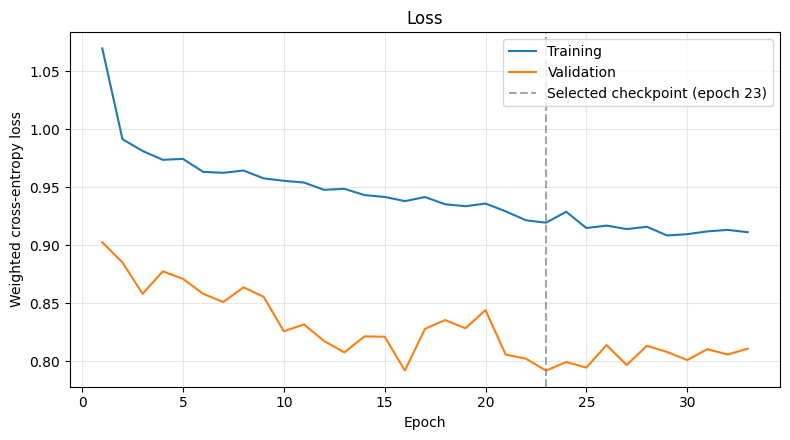

In [1158]:
plot_learning_curves(history)

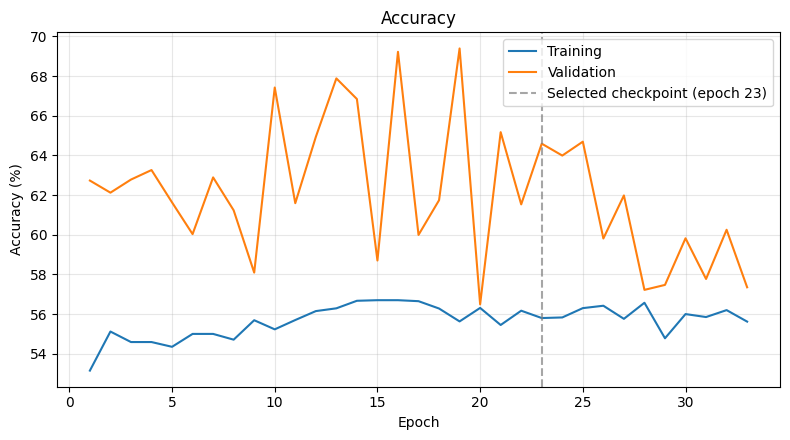

In [1159]:
plot_accuracy(history)

9 runs: ['2906-1', '3006-2', '0404', '2503', '1103', '1803', '1112', '1407-2', '1407-4']


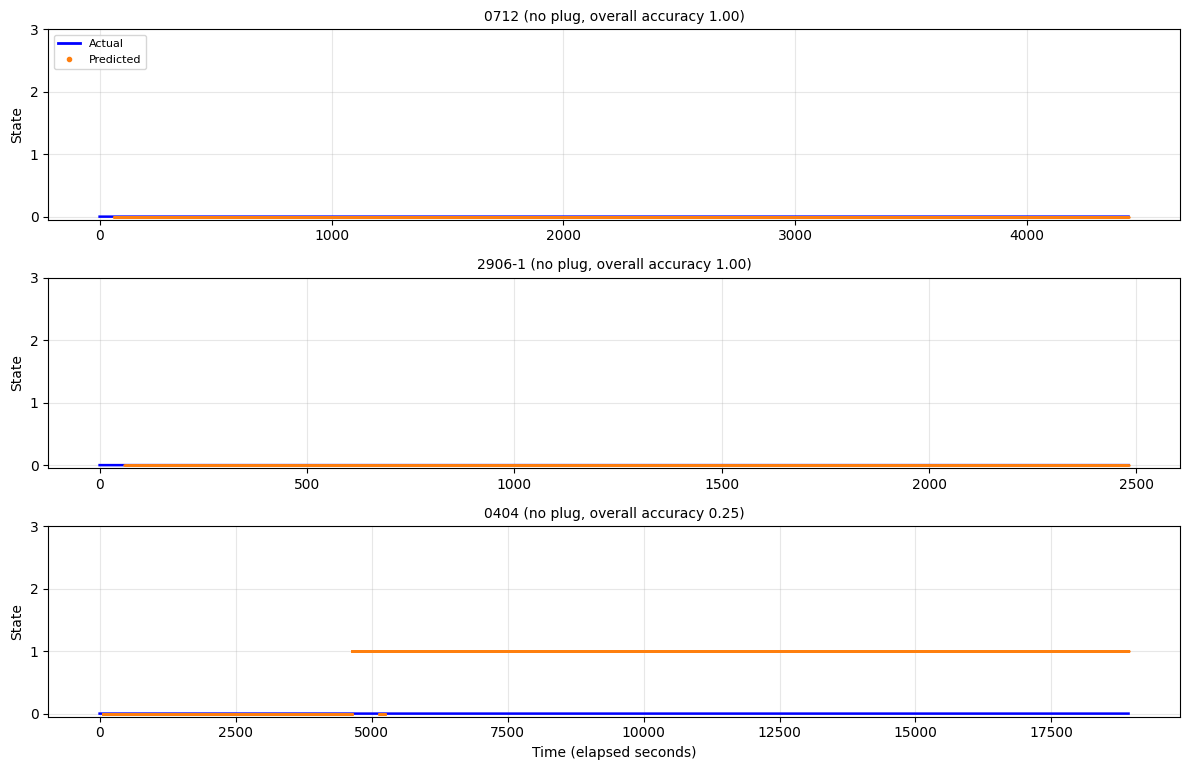

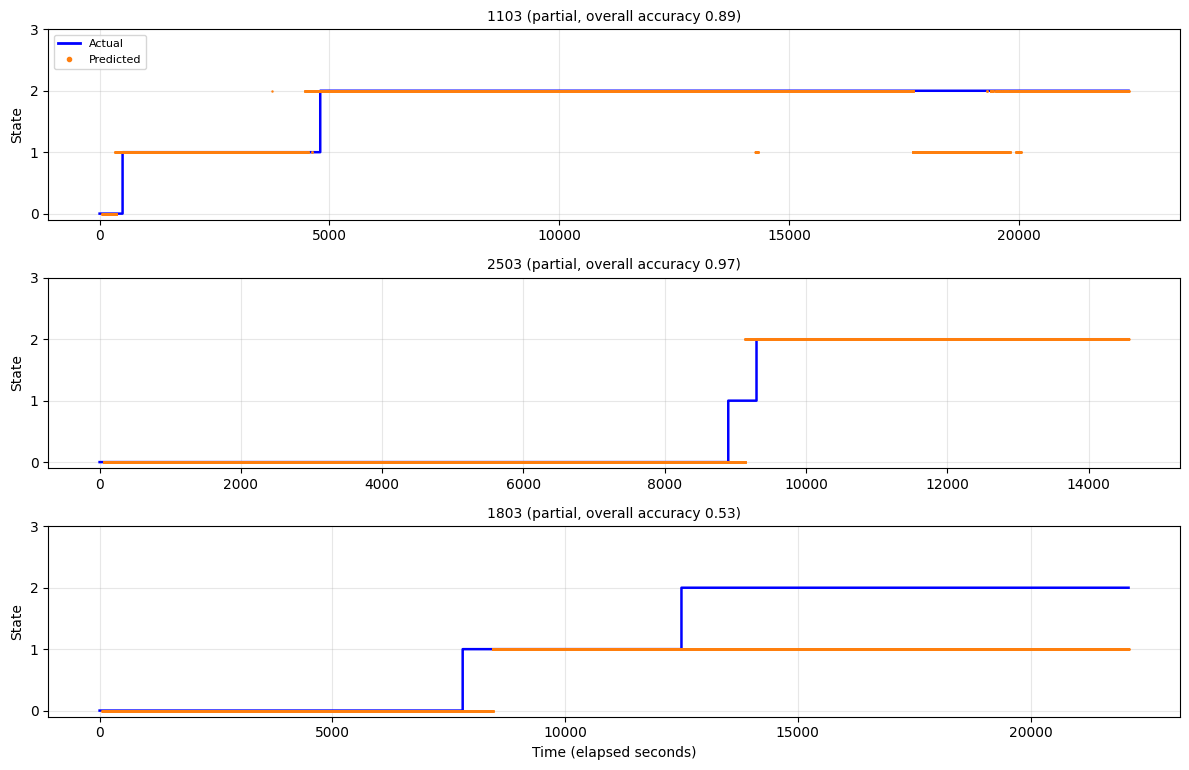

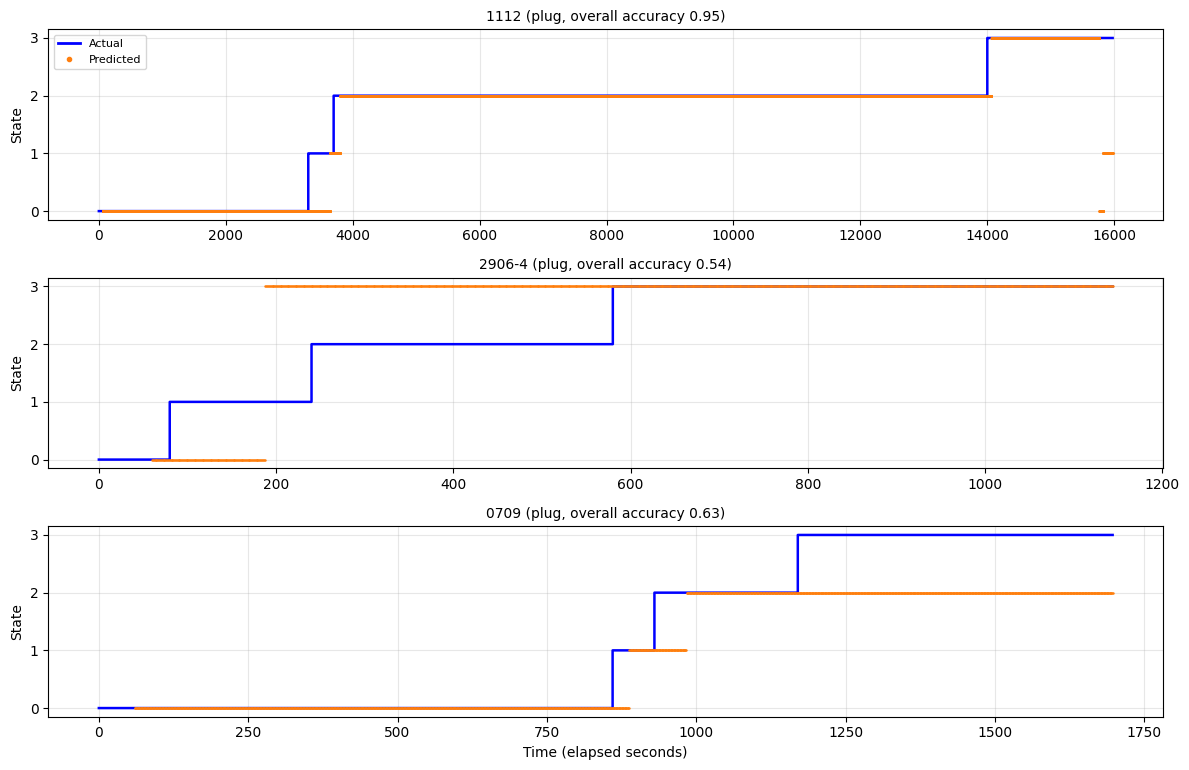

In [ ]:
model.load_state_dict(torch.load('../models/no_a_lstm.pth', map_location=device))
model.eval()

def predict_run(df, feature_cols, window=60):
    d = df.sort_values('elapsed_runtime_s').reset_index(drop=True)
    vals = d[feature_cols].values
    W = np.stack([vals[i-window:i] for i in range(window, len(vals))])
    Ws = scaler.transform(W.reshape(-1, W.shape[2])).reshape(W.shape)
    with torch.no_grad():
        p = model(torch.tensor(Ws, dtype=torch.float32).to(device)).argmax(1).cpu().numpy()
    pos = np.arange(window, len(vals))
    d['blk'] = (d['label'] != d['label'].shift(1)).cumsum()
    part = np.empty(len(d), dtype=object)
    for _, b in d.groupby('blk'):
        n = len(b); a, c = int(n*0.6), int(n*0.8)
        idx = b.index.values
        part[idx[:a]], part[idx[a:c]], part[idx[c:]] = 'train', 'val', 'test'
    labels = d['label'].values
    return d, [(int(i), part[i], int(labels[i]), int(p[k])) for k, i in enumerate(pos)]

# ---------- build results (all names distinct from other cells) ----------
res = {}
groups = ([(d, n, 'no plug') for d, n in zip(no_plug_dfs, no_plug_names)] +
          [(d, n, 'plug') for d, n in zip(plug_dfs, plug_names)] +
          [(d, n, 'partial') for d, n in zip(partial_plug_dfs, partial_plug_names)])
for df, name, grp in groups:
    d, rows = predict_run(df, ORIGINAL_FEATURES)
    acc = np.mean([t == p for _, _, t, p in rows]) if rows else np.nan
    res[name] = dict(group=grp, df=d, rows=rows, acc=acc)

# ---------- selection: two best and one worst per group ----------
# ranking that ignores runs with too few windows
def ranked(group, min_windows=300):
    return sorted([k for k, v in res.items()
                   if v['group'] == group and len(v['rows']) >= min_windows and not np.isnan(v['acc'])],
                  key=lambda k: res[k]['acc'])

#plug = ranked('plug')
chosen = []
for g in ('no plug', 'partial', 'plug'):
    r = ranked(g)                       # sorted worst to best, runs with too few windows excluded
    chosen += [r[-1], r[len(r)//2], r[0]]   # best, median, worst
print(len(chosen), "runs:", chosen)

def plot_pred_time_chunks(names, per_fig=3):
    named = ['0712', '2906-1', '0404', '1103', '2503', '1803', '1112', '2906-4', '0709']
    for k in range(0, len(named), per_fig):
        chunk = named[k:k + per_fig]
        fig, axes = plt.subplots(len(chunk), 1, figsize=(12, 2.6 * len(chunk)), sharey=True)
        for ax, name_i in zip(np.atleast_1d(axes), chunk):
            d_i, pr = res[name_i]['df'], res[name_i]['rows']
            ax.step(d_i.index, d_i['label'], where='post', color='blue', lw=1.8)
            ax.plot([t[0] for t in pr], [t[3] for t in pr], '.', ms=1.5, color='tab:orange')
            ax.set_yticks([0, 1, 2, 3])
            ax.set_title(f"{name_i} ({res[name_i]['group']}, overall accuracy {res[name_i]['acc']:.2f})", fontsize=10)
            ax.set_ylabel('State'); ax.grid(True, alpha=0.3)
        np.atleast_1d(axes)[-1].set_xlabel('Time (elapsed seconds)')
        np.atleast_1d(axes)[0].legend(
            handles=[plt.Line2D([], [], color='blue', lw=2, label='Actual'),
                     plt.Line2D([], [], marker='.', ls='', color='tab:orange', label='Predicted')],
            loc='upper left', fontsize=8)
        fig.tight_layout()
        plt.show()
        plt.close(fig)

plot_pred_time_chunks(chosen)